In [1]:
!cd ../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
    Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
  Using cached setuptools-82.0.1-py3-none-any.whl (1.0 MB)
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SO

# Overview of input GBIF cases

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

In [3]:
gbif_cases = pd.read_csv("../runtime/gbif_cases.csv")

In [4]:
gbif_cases.describe()

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,data_standard,year,best_oa_location.repository_institution,first_oa_location.repository_institution,best_oa_location,first_oa_location
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.0,179.000000,0.0,0.0,0.0,0.0
mean,89.000000,105.424581,142.273743,153.513966,153.513966,2.0,2024.000000,NaN,NaN,NaN,NaN
std,51.816986,63.071376,92.272483,99.156009,99.156009,0.0,1.323937,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,2.0,2022.000000,NaN,NaN,NaN,NaN
25%,44.500000,53.500000,62.000000,68.000000,68.000000,2.0,2023.000000,NaN,NaN,NaN,NaN
50%,89.000000,100.000000,139.000000,151.000000,151.000000,2.0,2024.000000,NaN,NaN,NaN,NaN
75%,133.500000,161.500000,217.500000,233.500000,233.500000,2.0,2025.000000,NaN,NaN,NaN,NaN
max,178.000000,212.000000,314.000000,336.000000,336.000000,2.0,2026.000000,NaN,NaN,NaN,NaN


In [5]:
for c in gbif_cases.columns:
    print(c)

Unnamed: 0.4
Unnamed: 0.3
Unnamed: 0.2
Unnamed: 0.1
Unnamed: 0
title
authors
source
published
open_access
peer_review
citation_type
countries_of_coverage
countries_of_researcher
keywords
literature_type
websites
identifiers
id
abstract
topics
added
gbif_download_key
literature_metadata
gbif_data_id_data
dataset_metadata
dwca_url
data_standard
doi_url
genre
has_repository_copy
is_oa
is_paratext
journal_is_in_doaj
journal_is_oa
journal_issn_l
journal_issns
journal_name
oa_locations
oa_locations_embargoed
oa_status
published_date
publisher
title_unp
updated
year
z_authors
best_oa_location.endpoint_id
best_oa_location.evidence
best_oa_location.host_type
best_oa_location.is_best
best_oa_location.license
best_oa_location.oa_date
best_oa_location.pmh_id
best_oa_location.repository_institution
best_oa_location.updated
best_oa_location.url
best_oa_location.url_for_landing_page
best_oa_location.url_for_pdf
best_oa_location.version
first_oa_location.endpoint_id
first_oa_location.evidence
first_oa

## Statistic constructs

In [6]:
from typing import TypedDict

class MetricSummary(TypedDict):
    mean: float
    median: float
    min: float
    max: float
    std: float

def get_summary(series: pd.Series) -> MetricSummary:
    """Computes standard descriptive statistics for a numeric series."""
    return {
        "mean": float(series.mean()),
        "median": float(series.median()),
        "min": float(series.min()),
        "max": float(series.max()),
        "std": float(series.std())
    }

## Preprocessing

In [7]:
import ast

In [8]:
gbif_cases["paper_download_info_dict"] = gbif_cases["paper_download_info"].apply(ast.literal_eval)

In [9]:
gbif_cases["dwca_zip_info_dict"] = gbif_cases["dwca_zip_info"].apply(ast.literal_eval)

## EDA

In [10]:
import pprint

### Basic Stats

In [11]:
class DwCArchiveStats(TypedDict):
    dwca_compressed_bytes: MetricSummary
    dwca_raw_bytes: MetricSummary
    dwca_file_count: MetricSummary
    dwca_compression_ratio: MetricSummary

class DataPaperStats(TypedDict):
    pdf_page_count: MetricSummary
    pdf_size_bytes: MetricSummary

In [12]:
def reduce_to_dwca_stats(df_dwca: pd.DataFrame) -> DwCArchiveStats:
    return {
        "dwca_compressed_bytes": get_summary(df_dwca['compressed_size_bytes']),
        "dwca_raw_bytes": get_summary(df_dwca['raw_size_bytes']),
        "dwca_file_count": get_summary(df_dwca['total_file_count']),
        "dwca_compression_ratio": get_summary(df_dwca['compression_ratio']),
    }

In [13]:
dwca_infos = gbif_cases["dwca_zip_info_dict"].apply(pd.Series)
dwca_stats = reduce_to_dwca_stats(dwca_infos)

In [14]:
pprint.pprint(dwca_stats)

{'dwca_compressed_bytes': {'max': 488503550.0,
                           'mean': 4439663.899441341,
                           'median': 102038.0,
                           'min': 2506.0,
                           'std': 38026006.08860089},
 'dwca_compression_ratio': {'max': 69.71,
                            'mean': 16.880893854748603,
                            'median': 14.29,
                            'min': 3.3,
                            'std': 10.618255283423487},
 'dwca_file_count': {'max': 6.0,
                     'mean': 3.5810055865921786,
                     'median': 3.0,
                     'min': 3.0,
                     'std': 0.7250548952267064},
 'dwca_raw_bytes': {'max': 5725386981.0,
                    'mean': 62521519.5698324,
                    'median': 1748313.0,
                    'min': 8682.0,
                    'std': 451357039.05675966}}


In [15]:
def reduce_to_datapaper_stats(df_pdf: pd.DataFrame) -> DataPaperStats:
    return {
        "pdf_page_count": get_summary(df_pdf['nr_pages']),
        "pdf_size_bytes": get_summary(df_pdf['file_size_bytes'] ),
    }

In [16]:
paper_infos = gbif_cases["paper_download_info_dict"].apply(pd.Series)
datapaper_stats = reduce_to_datapaper_stats(paper_infos)

In [17]:
pprint.pprint(datapaper_stats)

{'pdf_page_count': {'max': 46.0,
                    'mean': 14.134078212290502,
                    'median': 13.0,
                    'min': 1.0,
                    'std': 8.81354362627629},
 'pdf_size_bytes': {'max': 6490174.0,
                    'mean': 1097364.6033519553,
                    'median': 609919.0,
                    'min': 409.0,
                    'std': 1218961.5932249508}}


In [18]:
gbif_cases.groupby(["year", "source"]).count().unstack()

Unnamed: 0.4                                   \
source Annals of Forest Science Arxius de Miscel·lània Zoològica   
year                                                               
2022                        NaN                              1.0   
2023                        NaN                              2.0   
2024                        1.0                              2.0   
2025                        NaN                              2.0   
2026                        NaN                              1.0   

                                                                           \
source Biodiversity Data Journal Biota Colombiana Data Diversity Gigabyte   
year                                                                        
2022                        10.0              NaN  2.0       2.0      9.0   
2023                        14.0              3.0  4.0       5.0      3.0   
2024                        24.0              NaN  1.0       NaN      3.0   
2025                        26.0              NaN  NaN       1.0      NaN   
2026                        15.0              NaN  NaN       NaN      9.0   

                                                                \
source Journal of Limnology Management of Biological Invasions   
year                                                             
2022                    NaN                                NaN   
2023                   10.0                                NaN   
2024                    NaN                                1.0   
2025                    1.0                                NaN   
2026                    NaN                                NaN   

                                          ... dwca_zip_info_dict  \
source Medical and Veterinary Entomology  ...           Gigabyte   
year                                      ...                      
2022                                 NaN  ...                9.0   
2023                                 NaN  ...                3.0   
2024                                 NaN  ...                3.0   
2025                                 NaN  ...                NaN   
2026                                 1.0  ...                9.0   

                                                                \
source Journal of Limnology Management of Biological Invasions   
year                                                             
2022                    NaN                                NaN   
2023                   10.0                                NaN   
2024                    NaN                                1.0   
2025                    1.0                                NaN   
2026                    NaN                                NaN   

                                                                             \
source Medical and Veterinary Entomology MycoKeys PhytoKeys Scientific Data   
year                                                                          
2022                                 NaN      NaN       1.0             2.0   
2023                                 NaN      NaN       NaN             2.0   
2024                                 NaN      1.0       NaN             6.0   
2025                                 NaN      NaN       NaN             5.0   
2026                                 1.0      NaN       NaN             1.0   

                                     
source Specimen ZooKeys Zoosymposia  
year                                 
2022        NaN     NaN         NaN  
2023        NaN     NaN         1.0  
2024        2.0     NaN         NaN  
2025        NaN     1.0         NaN  
2026        4.0     NaN         NaN  

[5 rows x 1344 columns]

### Metadata Stats

In [19]:
class MetadataFileStats(TypedDict):
    schema: str
    
    grand_nr_elements: MetricSummary
    grand_nr_unique_elements: MetricSummary
    group_nr_elements: MetricSummary
    group_nr_unique_elements: MetricSummary
    total_nr_unique_elements: int
    
    grand_nr_attributes: MetricSummary
    grand_nr_unique_attributes: MetricSummary
    group_nr_attributes: MetricSummary
    group_nr_unique_attributes: MetricSummary
    total_nr_unique_attributes: int

    grand_nr_text_nodes: MetricSummary
    group_nr_text_nodes: MetricSummary

    grand_element_depth: MetricSummary
    group_element_depth: MetricSummary

    
    grand_element_fanout_degree: MetricSummary
    group_element_fanout_degree: MetricSummary
    
    grand_element_to_attribute_degree: MetricSummary
    group_element_to_attribute_degree: MetricSummary

    grand_text_content_length: MetricSummary
    group_text_content_length: MetricSummary

In [20]:
from dataclasses import dataclass
from typing import List, Optional, Set

@dataclass
class Element:
    tag: str
    depth: int
    nr_attributes: int
    nr_unique_attributes: int
    fanout: int  # Number of direct children
    text_length: int
    attribute_names: Set[str]

class MetadataOverview(TypedDict):
    elements: List[Element]

In [21]:
def is_hidden_file(fn: str) -> bool:
    return any((
        fn.startswith("__"),  # reserved/hidden files, e.g. __MACOSX
        fn.startswith("."),   # hidden files UNIX
    ))

def is_metadata_xml(fn: str) -> bool:
    """Check for xml but be aware of zip artifacts"""
    return fn.endswith(".xml") and not is_hidden_file(fn)

In [22]:
eml_files = gbif_cases["ground_truth_metadata_eml"]
dwc_files = gbif_cases["ground_truth_metadata_dwc"]

In [23]:
eml_files

0      ground_truth/data/000-6f97bcef-7324-3425-bb72-...
1      ground_truth/data/001-2fee34a0-a302-3c12-8916-...
2      ground_truth/data/002-325b19cf-6c16-3147-b8db-...
3      ground_truth/data/003-d72b6b4f-0fb1-301e-81d0-...
4      ground_truth/data/004-93ed8a30-2f05-37c7-a371-...
                             ...                        
174    ground_truth/data/208-8395f577-f4ec-3cc9-9d46-...
175    ground_truth/data/209-1cf45154-9800-31c6-ba38-...
176    ground_truth/data/210-99ee49cb-8bcd-39a4-895b-...
177    ground_truth/data/211-5ef32ca0-b247-30f8-aed8-...
178    ground_truth/data/212-74a27d9e-8cac-36c2-a743-...
Name: ground_truth_metadata_eml, Length: 179, dtype: str

In [24]:
from pathlib import Path

EXPERIMENT_BASE_DIR = "../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [57]:
def create_metadata_dataframes(file_series: pd.Series):
    # 1. Element-level (the one we built previously)
    el_df = parse_files_to_df(file_series)
    
    # 2. File-level (Aggregating elements by file_path)
    file_df = el_df.groupby("file_path").agg(
        nr_elements=('tag', 'count'),
        nr_unique_elements=('tag', 'nunique'),
        total_attributes=('nr_attributes', 'sum'),
        avg_depth=('depth', 'mean'),
        max_depth=('depth', 'max'),
        avg_fanout=('fanout', 'mean'),
        total_text_length=('text_length', 'sum'),
        nr_text_nodes=('text_length', lambda x: (x > 0).sum())
    ).reset_index()
    
    # Add calculated density columns for plotting
    file_df['attr_density'] = file_df['total_attributes'] / file_df['nr_elements']
    
    return el_df, file_df

In [58]:
def get_metadata_file_stats(el_df: pd.DataFrame, file_df: pd.DataFrame, schema: str) -> MetadataFileStats:
    # Grand (Pooled) - using Element DF
    total_unique_elements = el_df['tag'].nunique()
    total_unique_attrs = len(set().union(*el_df['attr_names']))
    
    # Group (Distribution of file properties) - using File DF
    return {
        "schema": schema,
        
        # Elements
        "grand_nr_elements": get_summary(file_df['nr_elements']), 
        "grand_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "group_nr_elements": get_summary(file_df['nr_elements']), 
        "group_nr_unique_elements": get_summary(file_df['nr_unique_elements']),
        "total_nr_unique_elements": total_unique_elements,
        
        # Attributes
        "grand_nr_attributes": get_summary(file_df['total_attributes']),
        "grand_nr_unique_attributes": get_summary(el_df.groupby("file_path")['nr_unique_attributes'].mean()), 
        "group_nr_attributes": get_summary(el_df.groupby("file_path")['nr_attributes'].mean()),
        "total_nr_unique_attributes": total_unique_attrs,

        # Structure & Content
        "grand_element_depth": get_summary(el_df['depth']),  # Pooled
        "group_element_depth": get_summary(file_df['avg_depth']), # Mean of means
        
        "grand_element_fanout_degree": get_summary(el_df['fanout']),
        "group_element_fanout_degree": get_summary(file_df['avg_fanout']),

        "grand_text_content_length": get_summary(el_df[el_df['text_length'] > 0]['text_length']),
        "group_text_content_length": get_summary(file_df['total_text_length']),
        
        "grand_nr_text_nodes": get_summary(file_df['nr_text_nodes']),
        "group_nr_text_nodes": get_summary(file_df['nr_text_nodes']), # Summarizing the counts
        
        "grand_element_to_attribute_degree": get_summary(el_df['nr_attributes']),
        "group_element_to_attribute_degree": get_summary(file_df['attr_density']),
    }

In [59]:
eml_element_overviews, eml_file_overviews = create_metadata_dataframes(eml_files.apply(grounded_path))

In [60]:
eml_element_overviews.describe()

,depth,nr_attributes,nr_unique_attributes,fanout,text_length
count,53666.000000,53666.000000,53666.000000,53666.000000,53666.000000
mean,3.823166,0.060858,0.060858,0.996665,34.029479
std,1.006971,0.354425,0.354425,9.408301,180.821566
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,0.000000,0.000000,0.000000,0.000000
50%,4.000000,0.000000,0.000000,0.000000,7.000000
75%,5.000000,0.000000,0.000000,2.000000,17.000000
max,8.000000,5.000000,5.000000,2052.000000,14326.000000


In [61]:
eml_file_overviews.describe()

,nr_elements,nr_unique_elements,total_attributes,avg_depth,max_depth,avg_fanout,total_text_length,nr_text_nodes,attr_density
count,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000,179.000000
mean,299.810056,69.016760,18.245810,3.582100,5.932961,0.994477,10202.379888,200.480447,0.077726
std,494.601131,12.220114,13.199248,0.308271,0.431847,0.003963,8481.407882,331.266761,0.034424
min,31.000000,25.000000,5.000000,2.794872,4.000000,0.967742,531.000000,17.000000,0.003320
25%,142.000000,63.000000,11.000000,3.397895,6.000000,0.992958,3856.000000,92.000000,0.054033
50%,206.000000,70.000000,15.000000,3.506711,6.000000,0.995146,8575.000000,135.000000,0.075581
75%,331.500000,76.500000,22.000000,3.746636,6.000000,0.996983,13711.500000,229.000000,0.095698
max,6326.000000,98.000000,126.000000,4.634366,8.000000,0.999842,59136.000000,4210.000000,0.265873


In [76]:
max_nr_elements = eml_file_overviews["nr_elements"].max()
print(max_nr_elements)
eml_files[eml_file_overviews["nr_elements"] == max_nr_elements].tolist()

6326


['ground_truth/data/156-ff4d2d74-150d-3d67-987a-b75098b106d1-download-data/eml.xml']

<Axes: ylabel='Frequency'>

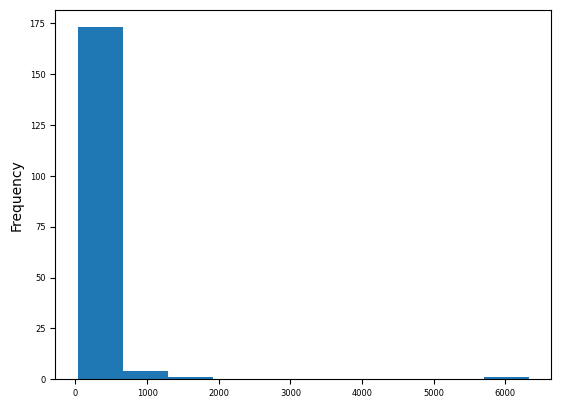

In [103]:
eml_file_overviews["nr_elements"].plot.hist()

In [91]:
eml_file_overviews.columns

Index(['file_path', 'nr_elements', 'nr_unique_elements', 'total_attributes',
       'avg_depth', 'max_depth', 'avg_fanout', 'total_text_length',
       'nr_text_nodes', 'attr_density'],
      dtype='str')

<Axes: >

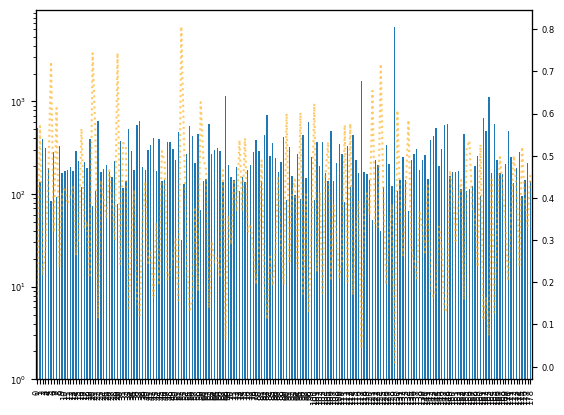

In [162]:
ax = eml_file_overviews[
    # 'nr_elements',
    'nr_unique_elements'
    # 'total_attributes', 
    # 'avg_depth', 
    # 'max_depth', 
    # 'avg_fanout', 
    # 'total_text_length',
    # 'nr_text_nodes', 
    # 'attr_density'
].plot.bar(color="skyblue", alpha=0.2, label="unique elements", ls="--", log=True)
twax = ax.twinx()
eml_file_overviews[
    'nr_elements'
    # 'nr_unique_elements', 
    # 'total_attributes', 
    # 'avg_depth', 
    # 'max_depth', 
    # 'avg_fanout', 
    # 'total_text_length',
    # 'nr_text_nodes', 
    # 'attr_density'
].plot.bar(ax = ax, color="tab:blue", label="total", log=True)
(
    eml_file_overviews[
        # 'nr_elements',
        'nr_unique_elements'
        # 'total_attributes', 
        # 'avg_depth', 
        # 'max_depth', 
        # 'avg_fanout', 
        # 'total_text_length',
        # 'nr_text_nodes', 
        # 'attr_density'
    ].div(eml_file_overviews[
        'nr_elements'
        # 'nr_unique_elements', 
        # 'total_attributes', 
        # 'avg_depth', 
        # 'max_depth', 
        # 'avg_fanout', 
        # 'total_text_length',
        # 'nr_text_nodes', 
        # 'attr_density'
    ])
).plot(color="orange", label="ratio", alpha=0.6, ls=":", ax=twax, secondary_y=True)

<Axes: >

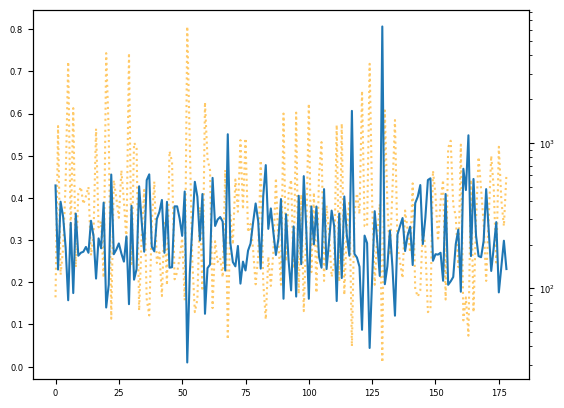

In [153]:
ax = (
    eml_file_overviews[
        # 'nr_elements',
        'nr_unique_elements'
        # 'total_attributes', 
        # 'avg_depth', 
        # 'max_depth', 
        # 'avg_fanout', 
        # 'total_text_length',
        # 'nr_text_nodes', 
        # 'attr_density'
    ].div(eml_file_overviews[
        'nr_elements'
        # 'nr_unique_elements', 
        # 'total_attributes', 
        # 'avg_depth', 
        # 'max_depth', 
        # 'avg_fanout', 
        # 'total_text_length',
        # 'nr_text_nodes', 
        # 'attr_density'
    ])
).plot(color="orange", label="ratio", alpha=0.6, ls=":")
twax = ax.twinx()
eml_file_overviews[
    'nr_elements'
    # 'nr_unique_elements', 
    # 'total_attributes', 
    # 'avg_depth', 
    # 'max_depth', 
    # 'avg_fanout', 
    # 'total_text_length',
    # 'nr_text_nodes', 
    # 'attr_density'
].plot(ax = twax, color="tab:blue", label="total", logy=True)

In [45]:
get_metadata_file_stats_from_df(eml_overviews, "eml")

{'schema': 'eml',
 'grand_nr_elements': {'mean': 299.8100558659218,
  'median': 206.0,
  'min': 31.0,
  'max': 6326.0,
  'std': 494.6011305337643},
 'grand_nr_unique_elements': {'mean': 69.01675977653632,
  'median': 70.0,
  'min': 25.0,
  'max': 98.0,
  'std': 12.220113674021755},
 'group_nr_elements': {'mean': 299.8100558659218,
  'median': 206.0,
  'min': 31.0,
  'max': 6326.0,
  'std': 494.6011305337643},
 'group_nr_unique_elements': {'mean': 69.01675977653632,
  'median': 70.0,
  'min': 25.0,
  'max': 98.0,
  'std': 12.220113674021755},
 'total_nr_unique_elements': 122,
 'grand_nr_attributes': {'mean': 0.06085789885588641,
  'median': 0.0,
  'min': 0.0,
  'max': 5.0,
  'std': 0.35442493350748566},
 'grand_nr_unique_attributes': {'mean': 0.06085789885588641,
  'median': 0.0,
  'min': 0.0,
  'max': 5.0,
  'std': 0.35442493350748566},
 'group_nr_attributes': {'mean': 0.07772604237334207,
  'median': 0.0755813953488372,
  'min': 0.0033196332595637054,
  'max': 0.26587301587301587,
  '

## Visualise

In [29]:
mpl.rc('xtick', labelsize=6)
mpl.rc('ytick', labelsize=6)

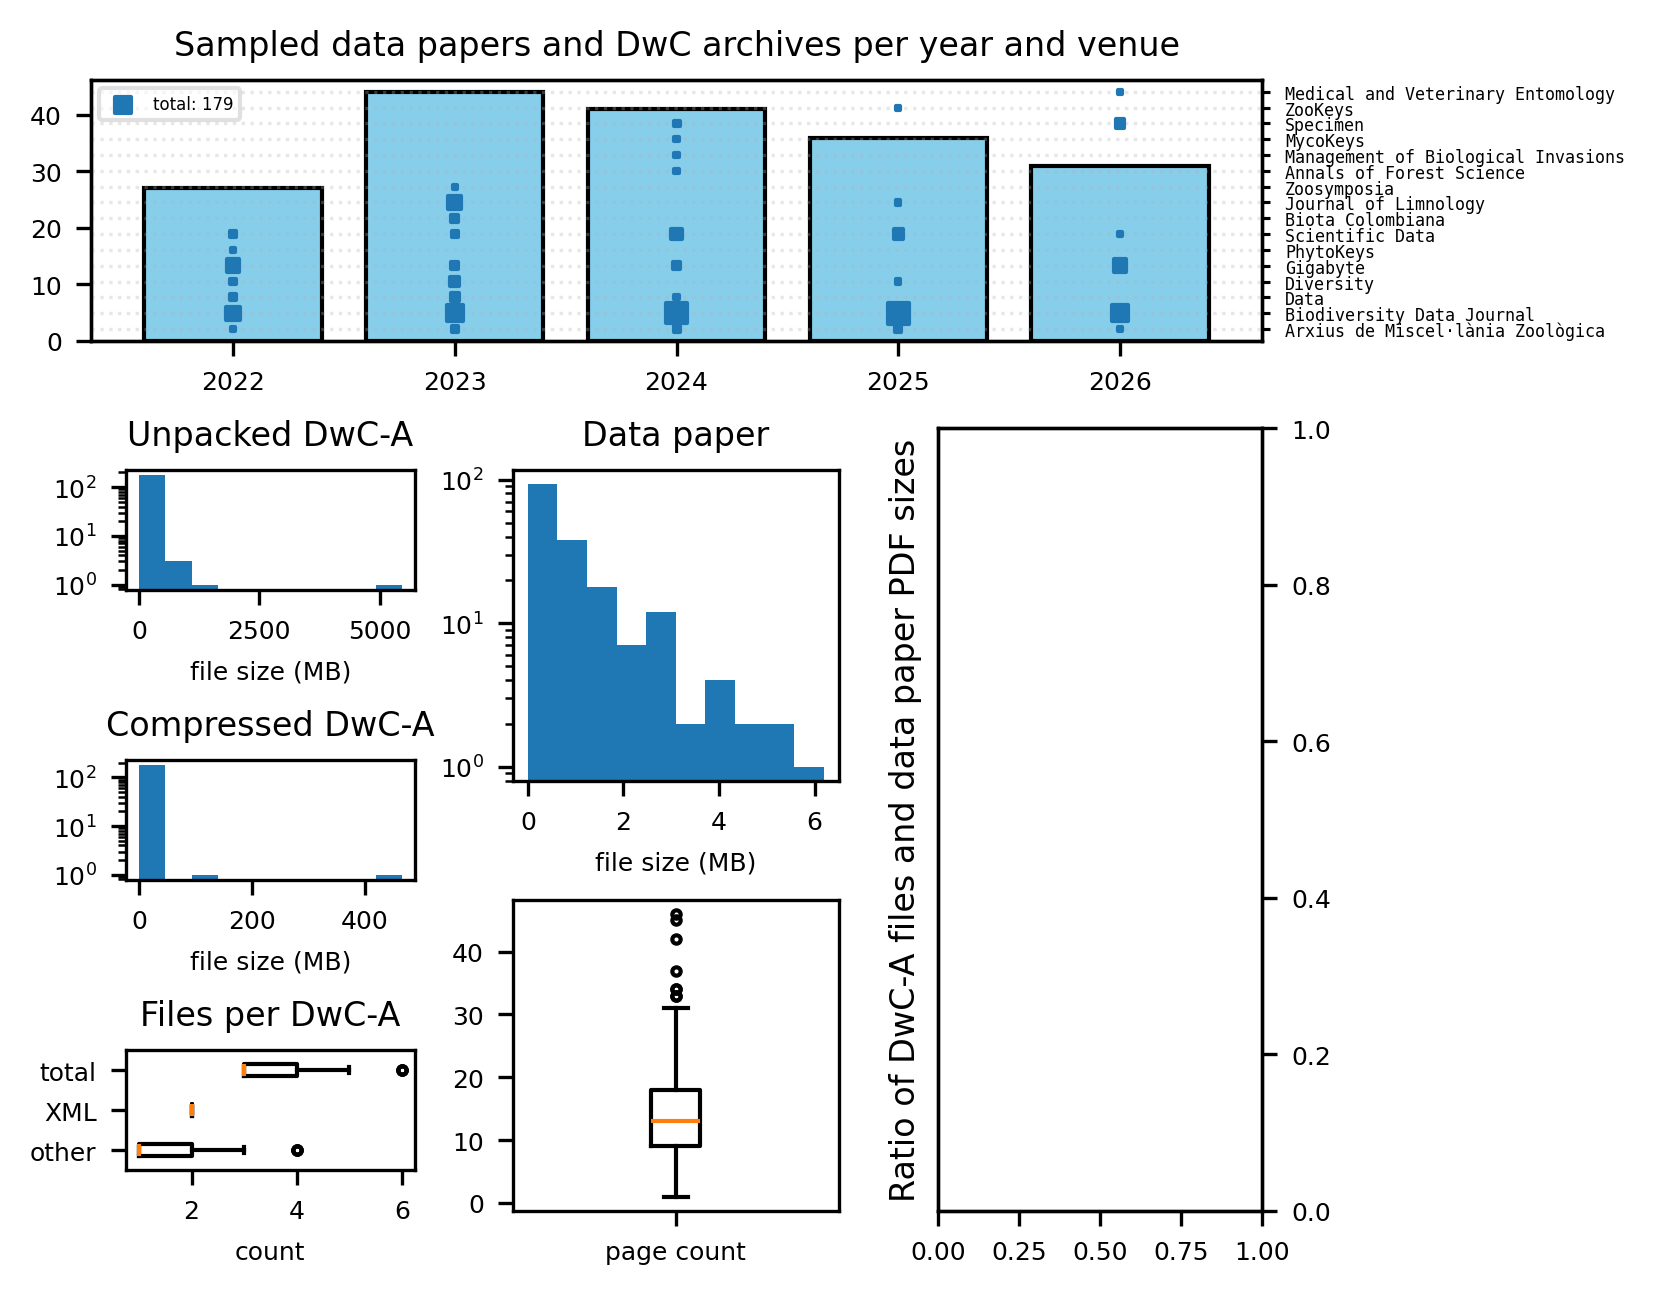

In [30]:
figsize = (5.4, 4.2)
dpi = 300
layout = """
    AAAAAA
    BBCCDD
    BBCCDD
    BBCCDD
"""

fig, axd = plt.subplot_mosaic(
    layout,
    figsize=figsize,
    dpi=dpi,
    constrained_layout=True
)

# Reusable subplot builder
def column_subplots(subplot_source, data):
    for i, (l, vsx, props, opts) in enumerate(data):
        ax = fig.add_subplot(subplot_source[i])
        if opts.get("boxplots", False):
            ax.boxplot(
                [vs for t, vs in vsx],
                tick_labels=[t for t, vs in vsx],
                flierprops=dict(markersize=2),
                **props
            )
            ax.set_xlabel(xl, fontsize=6) if (xl:=opts.get("xlabel", "")) else ...
            ax.set_ylabel(yl, fontsize=6) if (yl:=opts.get("ylabel", "")) else ...
        else:
            for t, vs in vsx:
                ax.hist(vs, **props, label=t)
                ax.set_xlabel(t, fontsize=6) if t else ...
        if opts.get("legend", False):
            ax.legend(fontsize=4)
        ax.set_title(l, size=8)

# Subplot 1: Year x Venue Histogram
axd['A'].set_title('Sampled data papers and DwC archives per year and venue', fontsize=8)
years = gbif_cases.groupby(["year"]).size().reset_index(name='count')
sizes = gbif_cases.groupby(["year", "source"]).size().reset_index(name='count')
axd['A'].bar(years["year"], years["count"], color='skyblue', edgecolor='black')
twinx_a = axd['A'].twinx()
twinx_a.grid(alpha=0.3, ls=":")
twinx_a.set_axisbelow(True)
twinx_a.tick_params(which='major', width=0.75, length=2, labelsize=4, labelfontfamily='monospace')
twinx_a.scatter(
    sizes["year"],
    sizes["source"],
    s=sizes["count"],
    marker="s",
    color="tab:blue",
    label=f"total: {gbif_cases.shape[0]}"
)
twinx_a.legend(fontsize=4, loc=2, framealpha=0.6)

# Subplot 2: DwC info
gs_b = axd['B'].get_subplotspec().subgridspec(3, 1)
column_subplots(
    gs_b,
    [
        ("Unpacked DwC-A", [("file size (MB)", dwca_infos["raw_size_bytes"] / (1024 ** 2))], dict(log=True), {}),
        ("Compressed DwC-A", [("file size (MB)", dwca_infos["compressed_size_bytes"] / (1024 ** 2))], dict(log=True), {}),
        (
            "Files per DwC-A",
            [
                ("other", dwca_infos["included_file_names"].apply(lambda fs: [f for f in fs if not is_metadata_xml(f)]).apply(len)),
                ("XML", dwca_infos["included_file_names"].apply(lambda fs: [f for f in fs if is_metadata_xml(f)]).apply(len)),
                ("total", dwca_infos["included_file_names"].apply(len)),
            ],
            dict(vert=False),
            dict(boxplots=True, xlabel="count")
        ),
    ],
)
axd['B'].axis('off') # Hide the parent container

# Subplot 3: Paper Info
# filesize, number of pages
gs_c = axd['C'].get_subplotspec().subgridspec(2, 1)
column_subplots(
    gs_c,
    [
        ("Data paper", [("file size (MB)", paper_infos["file_size_bytes"] / (1024 ** 2))], dict(log=True), {}),
        ("", [("page count", paper_infos["nr_pages"])], dict(vert=True), dict(boxplots=True)),
    ],
)
axd['C'].axis('off') # Hide the parent container


# Subplot 4: Size Ratio
axd['D'].yaxis.set_label_position("left")
axd['D'].yaxis.tick_right()
axd['D'].set_ylabel("Ratio of DwC-A files and data paper PDF sizes", size=8)
# axd['D'].hist(doc_ratios, orientation='horizontal', log=True, color='skyblue', edgecolor='black')
twiny_d = axd['D'].twiny()
twiny_d.grid(visible=False)
twiny_d.set_xticks([])
# twiny_d.boxplot(doc_ratios, flierprops=dict(markersize=2))

plt.savefig("ground-truth-data-eda.png")
plt.savefig("ground-truth-data-eda.pdf")
plt.show()